# SGOOTR transition-anchored inference parameters

This notebook reads the saved inference result for the transition-anchored SGOOTR tree and plots the fitted birth, death, and sampling parameters by state, along with the transition-probability matrix.

These are point estimates from the root-normalized inference. Transition times are shown in the inference time coordinate.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

result_relative_path = Path('data/sgootr/inference_transition_anchored/inference_result.txt')
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / result_relative_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(f'Could not find {result_relative_path} from {Path.cwd()}')
result_path = project_root / result_relative_path

state_names = ['NC', 'PT', 'LN']
parsed = {'transition_probabilities': {}, 'transition_times': []}
section = None
for raw_line in result_path.read_text().splitlines():
    line = raw_line.strip()
    if not line:
        continue
    if line.startswith('LL='):
        parsed['log_likelihood'] = float(line.split('=', 1)[1])
        section = None
    elif line.startswith('birth:'):
        parsed['birth'] = [float(value) for value in line.split(':', 1)[1].split()]
        section = None
    elif line.startswith('death:'):
        parsed['death'] = [float(value) for value in line.split(':', 1)[1].split()]
        section = None
    elif line.startswith('sampling:'):
        parsed['sampling'] = [float(value) for value in line.split(':', 1)[1].split()]
        section = None
    elif line == 'transitions:':
        section = 'transitions'
    elif line == 'transition_times:':
        section = 'transition_times'
    elif section == 'transitions':
        match = re.fullmatch(r'(\d+)->(\d+)\s+([+-]?[\d.eE+-]+)', line)
        if match:
            source, target = int(match.group(1)), int(match.group(2))
            parsed['transition_probabilities'][source, target] = float(match.group(3))
    elif section == 'transition_times':
        fields = line.split()
        if len(fields) == 2:
            parsed['transition_times'].append(float(fields[1]))

num_states = len(state_names)
for parameter_name in ('birth', 'death', 'sampling'):
    if len(parsed.get(parameter_name, [])) != num_states:
        raise ValueError(f'Expected {num_states} {parameter_name} estimates in {result_path}')

transition_matrix = np.zeros((num_states, num_states), dtype=float)
for (source, target), probability in parsed['transition_probabilities'].items():
    if source >= num_states or target >= num_states:
        raise ValueError(f'Unknown state ID in transition {source}->{target}')
    transition_matrix[source, target] = probability
if not np.allclose(transition_matrix.sum(axis=1), 1.0, atol=1e-8):
    raise ValueError('The transition probability matrix is not row-stochastic')

parameter_table = pd.DataFrame(
    {
        'Birth rate': parsed['birth'],
        'Death rate': parsed['death'],
        'Sampling probability': parsed['sampling'],
    },
    index=state_names,
)
parameter_table.index.name = 'State'
transition_times = parsed['transition_times']

print(f'Result: {result_path.relative_to(project_root)}')
print(f'Root-normalized log likelihood: {parsed["log_likelihood"]:.6f}')
print(f'Transition times (inference coordinate): {transition_times}')
display(parameter_table)

Result: data/sgootr/inference_transition_anchored/inference_result.txt
Root-normalized log likelihood: 48.401103
Transition times (inference coordinate): [0.8504478503, 0.9999005103]


,Birth rate,Death rate,Sampling probability
State,,,
NC,30.952540,22.348733,0.003756
PT,13.571878,3.788217,0.003756
LN,13.959272,4.333525,0.003756


## TLS-style composite sensitivity ranges

This follows the compact sensitivity workflow in `tls_NMP_NT_So_infer.ipynb`: profile the composite parameters, compute ranges at likelihood fractions $L/L_0 = 0.5, 0.1, 10^{-5}, 10^{-10}, 10^{-25}$, and plot the ranges around the fitted estimate. The SGOOTR likelihood is reconstructed from the same tree, per-edge transition events, fixed transition times, and root-normalization used by inference. Every profile varies one quantity while holding the other fitted parameters fixed.

SGOOTR has sequential allowed transitions NC→PT and PT→LN, not two competing transitions from one source. Therefore its center panel shows each allowed transition probability separately; a same-source transition ratio like the TLS Somite/NeuralTube ratio is not defined for this model.

In [2]:
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from src.dataprocessor import load_edges, load_nodes
from src.main2_given_transitions import (
    load_per_edge_transition_data,
    read_free_edges,
    read_transition_times,
)
from src.mle2_given_transitions import (
    PhylodynamicParameters,
    calculate_total_log_likelihood,
)
from src.tree_utils import (
    cut_tree,
    get_datastructure_for_likelihood_calculation,
    prepare_nx_tree,
)

torch.set_default_dtype(torch.float64)
inference_dir = project_root / 'data/sgootr/inference_transition_anchored'
inference_epochs = read_transition_times(str(inference_dir / 'transition_times.txt'))
if not np.allclose(inference_epochs, transition_times, rtol=0, atol=1e-12):
    raise ValueError('The saved inference epochs differ from the epochs in the result file')
free_transition_edges = read_free_edges(str(inference_dir / 'transition_edges.txt'))
with redirect_stdout(StringIO()):
    inference_tree = prepare_nx_tree(
        load_nodes(str(inference_dir / 'nodes.csv')),
        load_edges(str(inference_dir / 'edges.csv')),
    )
    per_edge_transitions = load_per_edge_transition_data(
        inference_dir / 'transitions.csv'
    )
    tree_levels, tree_hierarchy = cut_tree(inference_tree, inference_epochs)
    inference_data = get_datastructure_for_likelihood_calculation(
        tree_levels,
        tree_hierarchy,
        inference_epochs,
        num_states,
        per_edge_transition_data=per_edge_transitions,
    )

sensitivity_params = PhylodynamicParameters(
    num_states=num_states,
    free_edges=free_transition_edges,
    given_transition_times=inference_epochs,
    device=torch.device('cpu'),
    initial_birth_rates=[100.0] * num_states,
    initial_death_rates=[10.0] * num_states,
    initial_sampling_probabilities=[0.5] * num_states,
    initial_transition_probabilities=transition_matrix.tolist(),
)


def logit(probability):
    return torch.log(probability) - torch.log1p(-probability)


def set_sensitivity_parameters(birth_values, death_values, sampling_values, q_values):
    birth_tensor = torch.as_tensor(birth_values, dtype=torch.float64)
    death_tensor = torch.as_tensor(death_values, dtype=torch.float64)
    sampling_tensor = torch.as_tensor(sampling_values, dtype=torch.float64)
    q_tensor = torch.as_tensor(q_values, dtype=torch.float64)
    if torch.any(birth_tensor <= death_tensor):
        raise ValueError('Birth rates must exceed death rates in each sensitivity trial')
    if torch.any((sampling_tensor <= 0) | (sampling_tensor >= 1)):
        raise ValueError('Sampling probabilities must stay strictly between zero and one')
    if not torch.allclose(q_tensor.sum(dim=1), torch.ones(num_states), atol=1e-10):
        raise ValueError('Transition probabilities must remain row-stochastic')
    death_fraction = death_tensor / sensitivity_params.max_death_rate
    birth_fraction = (birth_tensor - death_tensor) / (
        sensitivity_params.max_birth_rate - death_tensor
    )
    if torch.any((death_fraction <= 0) | (death_fraction >= 1)):
        raise ValueError('Death rates must remain inside the inference parameter domain')
    if torch.any((birth_fraction <= 0) | (birth_fraction >= 1)):
        raise ValueError('Birth rates must remain inside the inference parameter domain')
    parameterized_transition_probabilities = torch.stack(
        [q_tensor[state, state] for state in range(num_states)]
        + [q_tensor[source, target] for source, target in free_transition_edges]
    )
    if torch.any(parameterized_transition_probabilities <= 0):
        raise ValueError('Fitted self/free transition probabilities must stay positive')
    transition_logits = parameterized_transition_probabilities.log()
    with torch.no_grad():
        sensitivity_params.death_raw.copy_(logit(death_fraction))
        sensitivity_params.birth_raw.copy_(logit(birth_fraction))
        sensitivity_params.sampling_raw.copy_(logit(sampling_tensor))
        sensitivity_params.transition_raw.copy_(transition_logits)


def evaluate_sgootr_likelihood(birth_values, death_values, sampling_values, q_values):
    set_sensitivity_parameters(birth_values, death_values, sampling_values, q_values)
    with torch.no_grad():
        return calculate_total_log_likelihood(
            params=sensitivity_params,
            trees=[inference_tree],
            datastructures=[inference_data],
            static_transition_times=inference_epochs,
            normalize_root_likelihood=True,
        ).item()


birth_baseline = np.asarray(parsed['birth'], dtype=float)
death_baseline = np.asarray(parsed['death'], dtype=float)
sampling_baseline = np.asarray(parsed['sampling'], dtype=float)
transition_baseline = np.asarray(transition_matrix, dtype=float)
baseline_log_likelihood = evaluate_sgootr_likelihood(
    birth_baseline,
    death_baseline,
    sampling_baseline,
    transition_baseline,
)
if not np.isclose(baseline_log_likelihood, parsed['log_likelihood'], rtol=0, atol=1e-6):
    raise ValueError(
        'Reconstructed likelihood does not match the saved inference result: '
        f'{baseline_log_likelihood} vs {parsed["log_likelihood"]}'
    )

likelihood_fractions = [0.5, 0.1, 1e-5, 1e-10, 1e-25]
likelihood_target_drops = -np.log(likelihood_fractions)
profile_grid_points = 121
rate_epsilon = 1e-8
probability_epsilon = 1e-8


def make_profile_grid(original, lower, upper, parameter_type, parameter_name):
    if not lower < upper or not lower <= original <= upper:
        raise ValueError(
            f'Invalid feasible grid for {parameter_name}: [{lower}, {upper}] '
            f'does not contain {original}'
        )
    if parameter_type in ('growth', 'scaled_sampling'):
        global_grid = np.geomspace(lower, upper, profile_grid_points)
        local_grid = np.geomspace(
            max(lower, original / 5.0),
            min(upper, original * 5.0),
            profile_grid_points,
        )
    else:
        global_grid = np.linspace(lower, upper, profile_grid_points)
        local_lower = max(lower, original / 5.0)
        local_upper = min(upper, original * 5.0)
        logit_lower = np.log(local_lower / (1.0 - local_lower))
        logit_upper = np.log(local_upper / (1.0 - local_upper))
        local_logits = np.linspace(logit_lower, logit_upper, profile_grid_points)
        local_grid = 1.0 / (1.0 + np.exp(-local_logits))
    return np.unique(np.concatenate((global_grid, local_grid, [original])))


parameter_specs = []
for state_index, state_name in enumerate(state_names):
    original_growth = birth_baseline[state_index] - death_baseline[state_index]
    maximum_growth = sensitivity_params.max_birth_rate - death_baseline[state_index]
    parameter_name = f'growth[{state_name}]'
    parameter_specs.append({
        'parameter': parameter_name,
        'parameter_type': 'growth',
        'parameter_index': state_index,
        'original_value': original_growth,
        'values': make_profile_grid(
            original_growth,
            rate_epsilon,
            maximum_growth * (1.0 - probability_epsilon),
            'growth',
            parameter_name,
        ),
    })

for state_index, state_name in enumerate(state_names):
    sampling_probability = sampling_baseline[state_index]
    original_scaled_sampling = sampling_probability * birth_baseline[state_index]
    parameter_name = f'scaled_sampling[{state_name}]'
    parameter_specs.append({
        'parameter': parameter_name,
        'parameter_type': 'scaled_sampling',
        'parameter_index': state_index,
        'original_value': original_scaled_sampling,
        'values': make_profile_grid(
            original_scaled_sampling,
            sampling_probability * (death_baseline[state_index] + rate_epsilon),
            sampling_probability * sensitivity_params.max_birth_rate * (
                1.0 - probability_epsilon
            ),
            'scaled_sampling',
            parameter_name,
        ),
    })

for source, target in free_transition_edges:
    other_outgoing_probability = sum(
        transition_baseline[source, state]
        for state in range(num_states)
        if state not in (source, target)
    )
    original_transition = transition_baseline[source, target]
    parameter_name = f'transition[{state_names[source]}→{state_names[target]}]'
    parameter_specs.append({
        'parameter': parameter_name,
        'parameter_type': 'transition',
        'parameter_index': target,
        'transition_edge': (source, target),
        'original_value': original_transition,
        'values': make_profile_grid(
            original_transition,
            probability_epsilon,
            1.0 - other_outgoing_probability - probability_epsilon,
            'transition',
            parameter_name,
        ),
    })

profile_rows = []
range_rows = []
metadata_rows = []
for specification in parameter_specs:
    parameter_name = specification['parameter']
    parameter_type = specification['parameter_type']
    parameter_index = specification['parameter_index']
    original_value = specification['original_value']
    parameter_values = specification['values']
    metadata_rows.append({
        'dataset': 'SGOOTR',
        'parameter': parameter_name,
        'parameter_type': parameter_type,
        'parameter_index': parameter_index,
        'original_value': original_value,
    })
    profile_loglikelihoods = []
    for candidate_value in parameter_values:
        trial_birth = birth_baseline.copy()
        trial_death = death_baseline.copy()
        trial_sampling = sampling_baseline.copy()
        trial_transition = transition_baseline.copy()
        if parameter_type == 'growth':
            trial_birth[parameter_index] = trial_death[parameter_index] + candidate_value
        elif parameter_type == 'scaled_sampling':
            trial_birth[parameter_index] = candidate_value / trial_sampling[parameter_index]
        else:
            source, target = specification['transition_edge']
            trial_transition[source, target] = candidate_value
            trial_transition[source, source] = 1.0 - sum(
                trial_transition[source, state]
                for state in range(num_states)
                if state != source
            )
        candidate_loglikelihood = evaluate_sgootr_likelihood(
            trial_birth,
            trial_death,
            trial_sampling,
            trial_transition,
        )
        if not np.isfinite(candidate_loglikelihood):
            raise FloatingPointError(
                f'Non-finite likelihood for {parameter_name}={candidate_value}'
            )
        profile_loglikelihoods.append(candidate_loglikelihood)
        profile_rows.append({
            'dataset': 'SGOOTR',
            'parameter': parameter_name,
            'parameter_type': parameter_type,
            'parameter_index': parameter_index,
            'parameter_value': candidate_value,
            'summed_log_likelihood': candidate_loglikelihood,
        })

    profile_loglikelihoods = np.asarray(profile_loglikelihoods, dtype=float)
    profile_drops = baseline_log_likelihood - profile_loglikelihoods
    best_index = int(np.argmin(profile_drops))
    best_value = float(parameter_values[best_index])

    def threshold_value(values, drops, target_drop):
        best = int(np.argmin(drops))
        lower_values = values[:best + 1][::-1]
        lower_drops = drops[:best + 1][::-1]
        higher_values = values[best:]
        higher_drops = drops[best:]

        def interpolate(branch_values, branch_drops):
            maximum_drop = float(np.max(branch_drops))
            domain_limit = float(branch_values[-1])
            if maximum_drop < target_drop:
                return domain_limit, maximum_drop, True
            for index in range(len(branch_values) - 1):
                left_drop = branch_drops[index]
                right_drop = branch_drops[index + 1]
                if min(left_drop, right_drop) <= target_drop <= max(left_drop, right_drop):
                    if left_drop == right_drop:
                        value = float(branch_values[index])
                    else:
                        fraction = (target_drop - left_drop) / (right_drop - left_drop)
                        value = float(
                            branch_values[index]
                            + fraction * (branch_values[index + 1] - branch_values[index])
                        )
                    at_domain_limit = np.isclose(value, domain_limit, rtol=1e-12, atol=0.0)
                    return value, maximum_drop, bool(at_domain_limit)
            return domain_limit, maximum_drop, True

        return (
            interpolate(lower_values, lower_drops),
            interpolate(higher_values, higher_drops),
        )

    for fraction, target_drop in zip(likelihood_fractions, likelihood_target_drops):
        (lower_value, lower_maximum_drop, lower_is_domain_limit), (
            higher_value, higher_maximum_drop, higher_is_domain_limit
        ) = threshold_value(parameter_values, profile_drops, float(target_drop))
        range_rows.append({
            'dataset': 'SGOOTR',
            'parameter': parameter_name,
            'parameter_type': parameter_type,
            'parameter_index': parameter_index,
            'likelihood_fraction': fraction,
            'original_value': original_value,
            'profile_best_value': best_value,
            'lower_parameter_value': lower_value,
            'higher_parameter_value': higher_value,
            'lower_maximum_drop_in_domain': lower_maximum_drop,
            'higher_maximum_drop_in_domain': higher_maximum_drop,
            'lower_bound_is_domain_limit': lower_is_domain_limit,
            'higher_bound_is_domain_limit': higher_is_domain_limit,
        })

output_dir = project_root / 'data/sgootr/figures/transition_anchored'
output_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame(profile_rows).to_csv(output_dir / 'composite_parameter_profiles.csv', index=False)
pd.DataFrame(range_rows).to_csv(
    output_dir / 'composite_parameter_value_ranges.csv', index=False
)
pd.DataFrame(metadata_rows).to_csv(
    output_dir / 'composite_parameter_metadata.csv', index=False
)
sensitivity_ranges = pd.DataFrame(range_rows)
print(
    f'Baseline root-normalized log likelihood: {baseline_log_likelihood:.6f}; '
    f'evaluated {len(profile_rows)} profile points.'
)
print(f'Saved composite profiles, ranges, and metadata to {output_dir}')
display(sensitivity_ranges[[
    'parameter',
    'likelihood_fraction',
    'lower_parameter_value',
    'higher_parameter_value',
    'lower_bound_is_domain_limit',
    'higher_bound_is_domain_limit',
]])

Baseline root-normalized log likelihood: 48.401103; evaluated 1936 profile points.
Saved composite profiles, ranges, and metadata to /Users/samin/workspace/phylodynamic-carta/data/sgootr/figures/transition_anchored


,parameter,likelihood_fraction,lower_parameter_value,higher_parameter_value,lower_bound_is_domain_limit,higher_bound_is_domain_limit
0,growth[NC],5.000000e-01,7.784639e+00,9.368944,False,False
1,growth[NC],1.000000e-01,7.138792e+00,10.052572,False,False
2,growth[NC],1.000000e-05,5.388150e+00,12.023545,False,False
3,growth[NC],1.000000e-10,4.038956e+00,13.651195,False,False
4,growth[NC],1.000000e-25,1.050236e+00,17.410074,False,False
5,growth[PT],5.000000e-01,9.478009e+00,10.076280,False,False
6,growth[PT],1.000000e-01,9.219685e+00,10.344675,False,False
7,growth[PT],1.000000e-05,8.534529e+00,11.084416,False,False
8,growth[PT],1.000000e-10,8.035670e+00,11.666197,False,False
9,growth[PT],1.000000e-25,7.046753e+00,12.894286,False,False


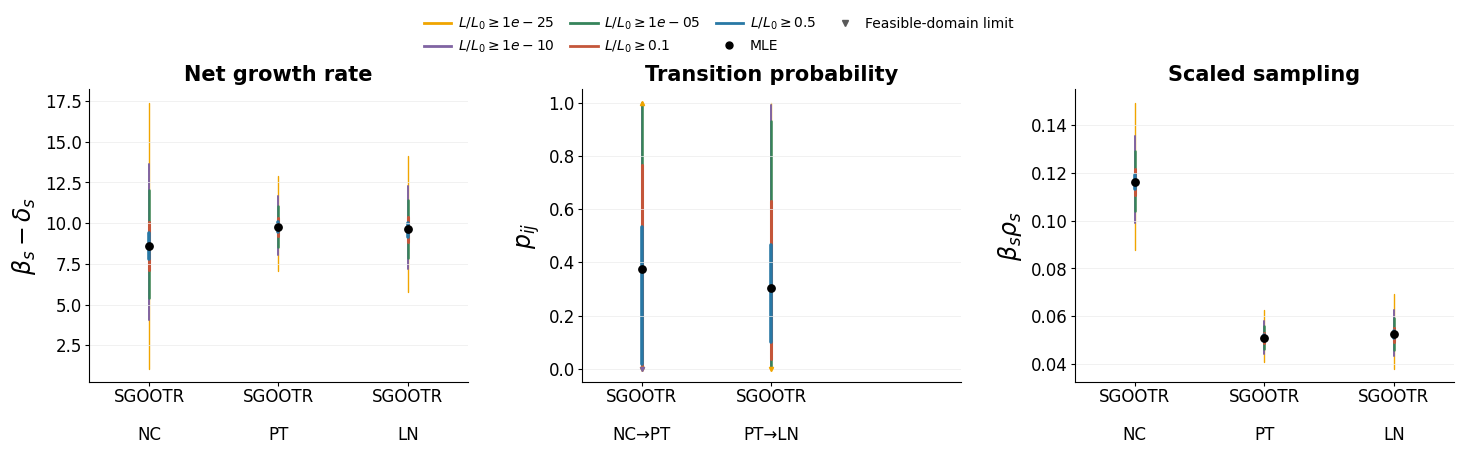

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

likelihood_fractions = [0.5, 0.1, 1e-5, 1e-10, 1e-25]
fraction_order = sorted(likelihood_fractions)
fraction_colors = {
    0.5: '#2878a5',
    0.1: '#c4563a',
    1e-5: '#36845b',
    1e-10: '#8064a2',
    1e-25: '#f0a500',
}
panels = [
    ('Net growth rate', 'growth', r'$\beta_s - \delta_s$'),
    ('Transition probability', 'transition', r'$p_{ij}$'),
    ('Scaled sampling', 'scaled_sampling', r'$\beta_s \rho_s$'),
]

range_path = output_dir / 'composite_parameter_value_ranges.csv'
metadata_path = output_dir / 'composite_parameter_metadata.csv'
ranges = pd.read_csv(range_path)
required_columns = {
    'lower_bound_is_domain_limit',
    'higher_bound_is_domain_limit',
}
missing_columns = required_columns.difference(ranges.columns)
if missing_columns:
    raise ValueError(
        f'Sensitivity range CSV is missing columns {sorted(missing_columns)}; '
        'rerun the preprocessing cell.'
    )
metadata = pd.read_csv(metadata_path)
expected_types = {parameter_type for _, parameter_type, _ in panels}
if set(metadata['parameter_type']) != expected_types:
    raise ValueError(
        f'Expected parameter types {sorted(expected_types)}; '
        f'found {sorted(metadata["parameter_type"].unique())}'
    )

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8), sharex=False)
group_spacing = 1.4
x_limits = (-0.65, 3.45)
for ax, (panel_title, parameter_type, y_label) in zip(axes, panels):
    parameters = (
        metadata[metadata['parameter_type'] == parameter_type]
        .sort_values('parameter_index')
        .reset_index(drop=True)
    )
    if parameters.empty:
        raise ValueError(f'No metadata found for parameter type {parameter_type}')
    tick_positions = []
    tick_labels = []
    group_annotations = []
    for parameter_position, (_, parameter_row) in enumerate(parameters.iterrows()):
        parameter = parameter_row['parameter']
        state_index = int(parameter_row['parameter_index'])
        if parameter_type == 'transition':
            group_label = parameter.split('[', 1)[1].rstrip(']')
        else:
            if not 0 <= state_index < len(state_names):
                raise ValueError(f'Unexpected state index {state_index} for {parameter}')
            group_label = state_names[state_index]
        x = parameter_position * group_spacing
        tick_positions.append(x)
        tick_labels.append('SGOOTR')
        group_annotations.append((x, group_label))
        parameter_ranges = ranges[ranges['parameter'] == parameter]
        fraction_values = parameter_ranges['likelihood_fraction'].to_numpy(dtype=float)
        mle_rows = metadata[metadata['parameter'] == parameter]
        if len(mle_rows) != 1:
            raise ValueError(f'Expected one metadata row for {parameter}; found {len(mle_rows)}')
        mle = float(mle_rows['original_value'].iloc[0])
        for linewidth, fraction in zip([1.0, 1.4, 1.8, 2.2, 2.6], fraction_order):
            matches = np.flatnonzero(
                np.isclose(fraction_values, fraction, rtol=1e-12, atol=0.0)
            )
            if matches.size != 1:
                raise KeyError(
                    f'Expected one row for {parameter}, fraction {fraction}; '
                    f'found {matches.size}'
                )
            row = parameter_ranges.iloc[matches[0]]
            lower = float(row['lower_parameter_value'])
            higher = float(row['higher_parameter_value'])
            if np.isfinite(lower) and np.isfinite(higher):
                ax.plot(
                    [x, x],
                    [lower, higher],
                    color=fraction_colors[fraction],
                    linewidth=linewidth,
                    solid_capstyle='round',
                    zorder=1,
                )
                if bool(row['lower_bound_is_domain_limit']):
                    ax.plot(
                        x, lower, marker='v', color=fraction_colors[fraction],
                        markersize=3, linestyle='', zorder=2,
                    )
                if bool(row['higher_bound_is_domain_limit']):
                    ax.plot(
                        x, higher, marker='^', color=fraction_colors[fraction],
                        markersize=3, linestyle='', zorder=2,
                    )
        ax.scatter(x, mle, s=28, marker='o', color='black', zorder=3)

    ax.set_title(panel_title, fontsize=15, fontweight='semibold', pad=6)
    ax.set_xlim(x_limits)
    ax.set_xticks(tick_positions, labels=tick_labels)
    ax.tick_params(axis='x', labelsize=12, length=3, pad=1)
    for group_center, group_label in group_annotations:
        ax.text(
            group_center,
            -0.15,
            group_label,
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='top',
            fontsize=12,
            clip_on=False,
        )
    ax.set_ylabel(y_label, fontsize=17, labelpad=5)
    ax.tick_params(axis='y', labelsize=12, length=3, pad=2)
    ax.grid(axis='y', color='0.92', linewidth=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fraction_handles = [
    Line2D(
        [0], [0], color=fraction_colors[fraction], linewidth=2,
        label=rf'$L/L_0 \geq {fraction:g}$',
    )
    for fraction in fraction_order
]
fraction_handles.append(
    Line2D([0], [0], marker='o', color='black', linestyle='', markersize=5, label='MLE')
)
fraction_handles.append(
    Line2D(
        [0], [0], marker='v', color='0.35', linestyle='', markersize=5,
        label='Feasible-domain limit',
    )
)
fig.legend(
    handles=fraction_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.0),
    ncol=4,
    frameon=False,
    fontsize=10,
    columnspacing=1.1,
    handletextpad=0.45,
)
fig.subplots_adjust(left=0.08, right=0.99, top=0.82, bottom=0.21, wspace=0.30)
fig.savefig(output_dir / 'SGOOTR_composite_sensitivity.pdf', bbox_inches='tight')
fig.savefig(output_dir / 'SGOOTR_composite_sensitivity.svg', bbox_inches='tight')
plt.show()